# 이전 문자를 기억하며 다음 문자 예측하기

**본인 사본을 만들어 실행·수정·기록하세요.**

- 이름: **⟦이윤호⟧**
- 학번: **⟦2022204025⟧**

[자습 자료](https://nii-lab.github.io/ko/courses/ai-applications/recurrent/index.html)

<!-- exercise-guidance:ai-applications/recurrent/execution -->
- Code Cell 실행: ▶ 또는 `Shift+Enter`, 위에서부터 순서대로.
- Text Cell 작성: 더블클릭 → `직접 입력` 작성 → `Shift+Enter`.
- 직접 작성 셀: 본인 코드 입력.
- 값 변경 후: 해당 셀과 뒤의 관련 셀 다시 실행.
<!-- /exercise-guidance:ai-applications/recurrent/execution -->


## 1. 문자 Batch 구성

사전 순서를 고정하고 입력·정답을 한 칸 이동합니다.

문자 Index는 0부터 시작합니다. One-hot의 길이와 최종 Class 수는 문자 사전의 크기이며, Hidden Size는 별도로 선택합니다. 세 문장은 공백·문장부호를 포함해 각각 9글자이며, 한 칸 이동하면 Input과 Target은 각각 8글자입니다. howareyou에서는 howareyo → owareyou를 사용합니다.

### A. 기준 예제 · 먼저 읽고 실행

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F

torch.manual_seed(42)
torch.set_num_threads(2)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)
sentences=['howareyou','whats up?','iamgreat.']
chars=sorted(set(''.join(sentences)));vocab={c:i for i,c in enumerate(chars)}
length=min(map(len,sentences))-1
ids=torch.tensor([[vocab[c] for c in s[:length]] for s in sentences])
Y=torch.tensor([[vocab[c] for c in s[1:length+1]] for s in sentences])
X=F.one_hot(ids,num_classes=len(chars)).float()
print('X:',X.shape,'Y:',Y.shape)
print('input:',sentences[0][:length],'target:',sentences[0][1:length+1])

Python: 3.12.3 | PyTorch: 2.12.0+cu130
X: torch.Size([3, 8, 17]) Y: torch.Size([3, 8])
input: howareyo target: owareyou


### B. 직접 수행

<!-- exercise-guidance:ai-applications/recurrent/activity-1 -->
1. 데이터 셀을 실행하고, 세 문장 각각의 Input 문자와 Target 문자를 두 행으로 출력하세요. 같은 열의 Input에 대해 Target이 원문에서 바로 다음 문자인지 대조하세요.
2. `X.shape`와 `Y.shape`를 출력하세요. 각 축에 문장 수·문자 수·Vocabulary 크기 중 해당하는 이름을 붙이세요.
3. Vocabulary의 문자 목록을 출력하고 공백과 문장부호가 포함되는 위치를 적으세요.
<!-- /exercise-guidance:ai-applications/recurrent/activity-1 -->

예상은 정확한 수치 대신 shape나 증가·감소 방향으로 적어도 됩니다. 설명은 아래 Text Cell에 기록하세요.


In [2]:
for sentence_index, sentence in enumerate(sentences):
    input_text = ''.join(chars[i] for i in ids[sentence_index].tolist())
    target_text = ''.join(chars[i] for i in Y[sentence_index].tolist())
    print(f'문장 {sentence_index + 1}: {sentence}')
    print('Input :', ' '.join(input_text))
    print('Target:', ' '.join(target_text))
    print()

print('X.shape =', tuple(X.shape), '→ (문장 수, 입력 문자 수, Vocabulary 크기)')
print('Y.shape =', tuple(Y.shape), '→ (문장 수, 정답 문자 수)')
print('Vocabulary (index: 문자):')
for index, char in enumerate(chars):
    label = repr(char) if char == ' ' else char
    print(f'{index}: {label}')


문장 1: howareyou
Input : h o w a r e y o
Target: o w a r e y o u

문장 2: whats up?
Input : w h a t s   u p
Target: h a t s   u p ?

문장 3: iamgreat.
Input : i a m g r e a t
Target: a m g r e a t .

X.shape = (3, 8, 17) → (문장 수, 입력 문자 수, Vocabulary 크기)
Y.shape = (3, 8) → (문장 수, 정답 문자 수)
Vocabulary (index: 문자):
0: ' '
1: .
2: ?
3: a
4: e
5: g
6: h
7: i
8: m
9: o
10: p
11: r
12: s
13: t
14: u
15: w
16: y


### C. 직접 기록 · 이 Text Cell을 더블클릭해서 수정

- 확인하거나 바꾼 조건: 각 문장에서 입력과 다음 글자 정답을 한 칸씩 짝지어 확인함
- 실행 전 예상: X에는 문장 수·문자 위치·Vocabulary 축이 있고 Y에는 문장 수·문자 위치 축이 있을 것으로 예상
- 실제 출력/그래프에서 확인한 값: `howareyo → owareyou`, `whats up → hats up?`, `iamgreat → amgreat.
- 예상과 차이 및 설명: 공백과 문장부호도 문자 사전에 포함되므로, 공백은  `\' \'`로 구분하고 문장부호도 각각 별도 index로 표현됨


## 2. RNN 학습

모든 시점의 문자를 예측합니다.

### A. 기준 예제 · 먼저 읽고 실행

Before training:    o o  
RNN 0 2.8256466388702393
RNN 100 0.005533785093575716
RNN 200 0.0020677547436207533
target: owareyou prediction: owareyou
target: hats up? prediction: hats up?
target: amgreat. prediction: amgreat.


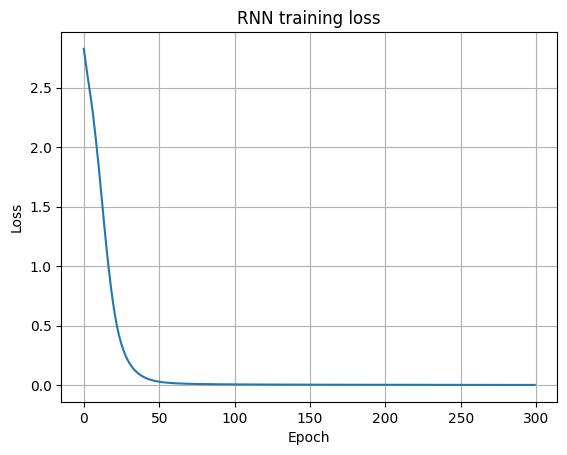

In [3]:
class CharModel(nn.Module):
    def __init__(self,kind,vocab_size,hidden=32):
        super().__init__();self.rnn=getattr(nn,kind)(vocab_size,hidden,batch_first=True);self.fc=nn.Linear(hidden,vocab_size)
    def forward(self,x):
        output,state=self.rnn(x);return self.fc(output)
def fit_char(kind,X,Y,epochs=300,lr=.01):
    torch.manual_seed(42);m=CharModel(kind,X.shape[-1]);opt=torch.optim.Adam(m.parameters(),lr=lr);losses=[]
    for epoch in range(epochs):
        logits=m(X);loss=F.cross_entropy(logits.reshape(-1,X.shape[-1]),Y.reshape(-1))
        opt.zero_grad();loss.backward();opt.step();losses.append(loss.item())
        if epoch%100==0:print(kind,epoch,loss.item())
    with torch.no_grad():pred=m(X).argmax(-1)
    return m,losses,pred
torch.manual_seed(42)
untrained = CharModel('RNN', X.shape[-1])
with torch.no_grad(): before_pred = untrained(X).argmax(-1)
print('Before training:', ''.join(chars[i] for i in before_pred[0]))
model,losses,pred=fit_char('RNN',X,Y)
for target,guess in zip(Y,pred):print('target:',''.join(chars[i] for i in target),'prediction:',''.join(chars[i] for i in guess))
plt.plot(losses);plt.title('RNN training loss');plt.xlabel('Epoch');plt.ylabel('Loss');plt.grid();plt.show()



### B. 직접 수행

<!-- exercise-guidance:ai-applications/recurrent/activity-2 -->
1. 학습 셀에서 출력한 `before_pred[0]`과 학습 후 `pred[0]`을 `Y[0]`과 문자별로 대조하세요. 학습 전후에 틀린 위치를 각각 적으세요.
2. 학습한 `model`에 `X[:, :4, :]`, `X[:, :6, :]`, `X[:, :8, :]`을 각각 넣으세요. 재학습 없이 `torch.no_grad()` 안에서 실행합니다.
3. 입력 Sequence 길이·전체 입력 shape·전체 출력 shape를 세 행의 표로 기록하세요. 길이가 바뀔 때 함께 바뀌는 출력 축을 표시하세요.
<!-- /exercise-guidance:ai-applications/recurrent/activity-2 -->

예상은 정확한 수치 대신 shape나 증가·감소 방향으로 적어도 됩니다. 설명은 아래 Text Cell에 기록하세요.


In [4]:
before_text = ''.join(chars[i] for i in before_pred[0].tolist())
target_text = ''.join(chars[i] for i in Y[0].tolist())
after_text = ''.join(chars[i] for i in pred[0].tolist())
print('첫 문장 정답:', ' '.join(target_text))
print('학습 전 예측:', ' '.join(before_text))
print('학습 후 예측:', ' '.join(after_text))
print('학습 전 틀린 위치(0부터):', [i for i, (a, b) in enumerate(zip(before_text, target_text)) if a != b])
print('학습 후 틀린 위치(0부터):', [i for i, (a, b) in enumerate(zip(after_text, target_text)) if a != b])

shape_rows = []
model.eval()
with torch.no_grad():
    for sequence_length in (4, 6, 8):
        x_part = X[:, :sequence_length, :]
        output = model(x_part)
        shape_rows.append((sequence_length, tuple(x_part.shape), tuple(output.shape)))
for sequence_length, input_shape, output_shape in shape_rows:
    print(f'Sequence 길이 {sequence_length}: 입력 {input_shape} → 출력 {output_shape}')


첫 문장 정답: o w a r e y o u
학습 전 예측:       o   o    
학습 후 예측: o w a r e y o u
학습 전 틀린 위치(0부터): [0, 1, 2, 3, 4, 5, 6, 7]
학습 후 틀린 위치(0부터): []
Sequence 길이 4: 입력 (3, 4, 17) → 출력 (3, 4, 17)
Sequence 길이 6: 입력 (3, 6, 17) → 출력 (3, 6, 17)
Sequence 길이 8: 입력 (3, 8, 17) → 출력 (3, 8, 17)


### C. 직접 기록 · 이 Text Cell을 더블클릭해서 수정

- 확인하거나 바꾼 조건:  입력 Sequence 길이 (4,6,8)
- 실행 전 예상: 입력 shape은 `(3, 길이, 17)`, 출력 shape도 `(3, 길이, 17)`이어서 길이 축만 4·6·8로 바뀔 것으로 예상
- 실제 출력/그래프에서 확인한 값: 학습 전 첫 문장 예측은 `   o o  `로 정답 `owareyou`와 8개 위치 모두 변경됨.
학습 후 예측은 `owareyou`로 정답과 일치하였고, 길이별 입력/출력 shape = `(3, 4, 17) → (3, 4, 17)`, `(3, 6, 17) → (3, 6, 17)`, `(3, 8, 17) → (3, 8, 17)`
- 예상과 차이 및 설명: 예상과 일치


## 반복 숙달 · 실행 전에 판단하기

앞의 직접 수행에서 비교한 조건 세 가지를 이 표에 정리하세요. 이미 수행한 실험을 다시 추가할 필요는 없습니다. 비교가 부족하면 한 조건만 바꾸어 보충하세요.

| 변경 조건 | 예상 shape/수치/결과 | 실제 결과 | 오류가 있었다면 원인 |
|---|---|---|---|
| 4 | 길이축 4 | 예상과 일치 | - |
| 6 | 길이축 6 | 예상과 일치 | - |
| 8 | 길이축 8 | 예상과 일치 | - |

In [5]:
print('Sequence 길이 | 입력 shape | 출력 shape')
for sequence_length, input_shape, output_shape in shape_rows:
    print(f'{sequence_length:>14} | {str(input_shape):>14} | {str(output_shape):>15}')

Sequence 길이 | 입력 shape | 출력 shape
             4 |     (3, 4, 17) |      (3, 4, 17)
             6 |     (3, 6, 17) |      (3, 6, 17)
             8 |     (3, 8, 17) |      (3, 8, 17)
원래 X: Input (3, 8, 17) → Output (3, 8, 17)
축을 바꾼 X.transpose(0, 1): Input (8, 3, 17) → Output (8, 3, 17)


## 선택 실습 · 오류의 원인을 찾아 코드 고치기

<!-- exercise-guidance:ai-applications/recurrent/optional -->
**Batch와 Sequence 축을 서로 바꾼 경우**

1. 세 문장을 사용하는 RNN 학습까지 마친 뒤, 노트북 맨 아래에 Code Cell을 추가하고 다음 코드를 실행하세요.
   
   ```python
   for debug_input in [X, X.transpose(0, 1)]:
       with torch.no_grad():
           debug_output = model(debug_input)
       print("Input:", debug_input.shape, "Output:", debug_output.shape,
             "Target:", Y.shape)
   ```
2. Text Cell에 각 호출에서 모델이 해석하는 Batch 크기와 Sequence 길이를 적으세요. `batch_first=True`에서는 첫 번째 축이 Batch입니다. 세 문장을 각각 하나의 Sequence로 처리하는 입력은 어느 것이며, 다른 호출도 오류 없이 실행되는 이유를 설명하세요.
<!-- /exercise-guidance:ai-applications/recurrent/optional -->

## 저장 전 확인

1. 작성란과 출력·그래프를 확인하고 새 런타임에서 전체 셀을 순서대로 실행하세요.
2. 본인 Drive에 저장한 뒤 `.ipynb`로 내려받으세요.

<!-- exercise-guidance:ai-applications/recurrent/submission -->
코드, 실제 Output·그래프, 직접 작성한 해석을 포함하세요.  제출은 KLAS를 이용하며 기한은 학기 일정과 최신 공지를 확인합니다.

파일명: `이름_학번_12주차.ipynb`.
<!-- /exercise-guidance:ai-applications/recurrent/submission -->


In [ ]:
for debug_input in [X, X.transpose(0, 1)]:
    with torch.no_grad():
        debug_output = model(debug_input)
    print("Input:", debug_input.shape, "Output:", debug_output.shape,"Target:", Y.shape)

### 선택 실습 결과 해석

`batch_first=True`이므로 원래 입력 `X`의 shape `(3, 8, 17)`은 Batch 3개, Sequence 길이 8로 해석됨

축을 바꾼 입력은 `(8, 3, 17)`이므로 Batch 8개, Sequence 길이 3으로 해석되고 출력도 `(8, 3, 17)`로 기록 

두 경우 모두 입력 feature 수가 17로 맞아 연산 자체는 가능하지만, 전치한 입력은 세 문장을 각각 하나의 Sequence로 처리하는 구조가 아닙니다. 의도한 문장별 처리는 원래 `X`의 축 순서입니다.
